**1. Entorno y datos de entrenamiento**
Carga el panel verificado y conserva solo las filas elegibles de entrenamiento (año objetivo ≤ 2021); registra versiones.

In [1]:
from pathlib import Path
import sys, json, unittest
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/feature_engineering.py').is_file())
sys.path.insert(0, str(ROOT))
import src.ablacion_variables as ab
import src.comparacion_modelos as cm
pd.set_option('display.width', 220, 'display.max_columns', 40, 'display.max_colwidth', 90, 'display.max_rows', 80)
train, cols = ab.cargar_entrenamiento()
print('Filas de entrenamiento:', len(train), '| atributos:', len(cols), '| año objetivo máx.:', train.anio_objetivo.max())
print(cm.protocolo()['versiones'])

Filas de entrenamiento: 2869 | atributos: 26 | año objetivo máx.: 2021
{'python': '3.12.15', 'scikit-learn': '1.9.1', 'numpy': '2.5.4', 'pandas': '3.0.6'}


Se usan las 2.869 filas de entrenamiento y los 26 atributos de E2, con scikit-learn 1.9.1 del entorno existente; no se instaló nada.

**2. Protocolo declarado antes de ejecutar**
Rejillas exactas, máximo de configuraciones, desempates hacia lo más simple, tratamiento de fallos y regla de recomendación.

In [2]:
cfg = cm.protocolo()
print(json.dumps({k: cfg[k] for k in ['validacion', 'elastic_net', 'boosting', 'maximo_configuraciones', 'desempate', 'fallos', 'regla_recomendacion']}, ensure_ascii=False, indent=1))

{
 "validacion": {
  "anios_externos": [
   2017,
   2018,
   2019,
   2020,
   2021
  ],
  "entrenamiento_externo": "anio_objetivo < año externo, misma moneda",
  "interna": "3 últimos años antes del externo, ventana expansiva, >= 8 años de historia (mismo código que la revisión)",
  "criterio": "promedio simple del RMSE de los años internos",
  "aleatoria": false
 },
 "elastic_net": {
  "pipeline": "TransformedTargetRegressor(Pipeline(ColumnTransformer(mediana keep_empty_features + StandardScaler), ElasticNet), transformer=StandardScaler()): el objetivo se estandariza con la media y desviación del entrenamiento; predicciones en unidades originales",
  "alpha": [
   0.001,
   0.01,
   0.1,
   1.0
  ],
  "l1_ratio": [
   0.1,
   0.5,
   0.9
  ],
  "max_iter": 10000,
  "tol": 0.0001,
  "configuraciones": 12
 },
 "boosting": {
  "algoritmo": "HistGradientBoostingRegressor",
  "max_depth": [
   2,
   3
  ],
  "max_iter": [
   100,
   300
  ],
  "l2_regularization": [
   0.0,
   10.0
  ],


Ridge tiene 8 configuraciones, Elastic Net 12 y boosting 8. Un modelo nuevo se recomienda solo si mejora el RMSE anual medio al menos un 1 % en 4 de 5 años, sin empeorar el MAE, frente a la media histórica, la persistencia y Ridge.

**3. Ejecución completa**
`run()` realiza las búsquedas internas, los ajustes externos y las comparaciones, y escribe `reports/sprint_08/comparacion_modelos/`.

In [3]:
salidas = cm.run()
display(salidas['pliegues_externos.csv'])
print('Reproducción de la revisión (dif. relativa máx.):', cm.verificar_contra_revision(salidas['predicciones_externas.csv']))

,moneda,anio_externo,n_externo,empresas_externo
0,D lares,2017,21,21
1,D lares,2018,25,25
2,D lares,2019,26,26
3,D lares,2020,24,24
4,D lares,2021,23,23
5,Soles,2017,177,177
6,Soles,2018,169,169
7,Soles,2019,162,162
8,Soles,2020,161,161
9,Soles,2021,160,160


Reproducción de la revisión (dif. relativa máx.): {'media_historica': 8.215236474396787e-16, 'persistencia': 8.215236474396787e-16, 'ridge': 4.482974128505536e-15}


Cada año externo tiene las mismas filas para los cinco procedimientos (21–26 en dólares; 160–177 en soles). La media histórica, la persistencia y Ridge reproducen exactamente las predicciones de la revisión anterior.

**4. Hiperparámetros elegidos y convergencia**
Configuración elegida por año externo y estado de convergencia de todas las búsquedas internas.

In [4]:
display(salidas['hiperparametros_elegidos.csv'].pivot_table(index=['moneda', 'anio_externo'], columns='modelo', values='configuracion', aggfunc='first'))
b = salidas['busquedas_internas.csv']
print('Configuraciones internas evaluadas:', len(b), '| no válidas:', int((~b.valida).sum()))
display(salidas['tiempos'].groupby(['moneda', 'modelo'])[['segundos_busqueda_interna', 'segundos_ajuste_externo']].mean().round(2))

modelo                                                                    boosting                       elastic_net                 ridge
moneda  anio_externo                                                                                                                      
D lares 2017          {"max_depth": 2, "max_iter": 100, "l2_regularization": 10.0}   {"alpha": 1.0, "l1_ratio": 0.9}    {"alpha": 10000.0}
        2018          {"max_depth": 2, "max_iter": 100, "l2_regularization": 10.0}   {"alpha": 1.0, "l1_ratio": 0.9}     {"alpha": 1000.0}
        2019          {"max_depth": 2, "max_iter": 100, "l2_regularization": 10.0}   {"alpha": 1.0, "l1_ratio": 0.1}     {"alpha": 1000.0}
        2020           {"max_depth": 2, "max_iter": 100, "l2_regularization": 0.0}   {"alpha": 1.0, "l1_ratio": 0.1}     {"alpha": 1000.0}
        2021          {"max_depth": 2, "max_iter": 100, "l2_regularization": 10.0}   {"alpha": 1.0, "l1_ratio": 0.1}     {"alpha": 1000.0}
Soles   2017          {"max_depth": 3, "max_iter": 100, "l2_regularization": 10.0}   {"alpha": 1.0, "l1_ratio": 0.9}  {"alpha": 1000000.0}
        2018          {"max_depth": 3, "max_iter": 100, "l2_regularization": 10.0}   {"alpha": 1.0, "l1_ratio": 0.9}  {"alpha": 1000000.0}
        2019          {"max_depth": 3, "max_iter": 100, "l2_regularization": 10.0}   {"alpha": 1.0, "l1_ratio": 0.9}  {"alpha": 1000000.0}
        2020          {"max_depth": 3, "max_iter": 100, "l2_regularization": 10.0}   {"alpha": 1.0, "l1_ratio": 0.9}    {"alpha": 10000.0}
        2021          {"max_depth": 3, "max_iter": 100, "l2_regularization": 10.0}  {"alpha": 0.01, "l1_ratio": 0.5}    {"alpha": 10000.0}

Configuraciones internas evaluadas: 280 | no válidas: 0


segundos_busqueda_interna  segundos_ajuste_externo
moneda  modelo                                                         
D lares boosting                          2.01                     0.04
        elastic_net                       0.28                     0.01
        ridge                             0.02                     0.00
Soles   boosting                          2.76                     0.10
        elastic_net                       0.38                     0.01
        ridge                             0.03                     0.01

Todas las configuraciones convergen. Elastic Net elige casi siempre alpha = 1, el máximo de su rejilla, lo que lo acerca a la media. Boosting elige 100 iteraciones, regularización l2 = 10 (salvo dólares 2020, con l2 = 0) y profundidad 2 (dólares) o 3 (soles). Las rejillas no se amplían tras ver resultados.

**5. Métricas externas por procedimiento**
Promedio simple de RMSE y MAE anuales (criterio) y métricas concatenadas (ponderan por filas).

In [5]:
display(salidas['resumen_procedimientos.csv'].sort_values(['moneda', 'RMSE_anual_medio']).round(0))
display(salidas['metricas_por_anio.csv'].pivot_table(index=['moneda', 'anio_externo'], columns='procedimiento', values='RMSE').round(0))

,moneda,procedimiento,anios,n,RMSE_anual_medio,MAE_anual_medio,RMSE_concatenado,MAE_concatenado
3,D lares,persistencia,5,119,192066.0,89316.0,202295.0,88174.0
0,D lares,boosting,5,119,234081.0,122406.0,249959.0,120985.0
4,D lares,ridge,5,119,247885.0,128570.0,272219.0,126001.0
1,D lares,elastic_net,5,119,259556.0,137866.0,276917.0,135850.0
2,D lares,media_historica,5,119,288696.0,151261.0,309286.0,149730.0
5,Soles,boosting,5,829,911069.0,233320.0,1017829.0,230565.0
9,Soles,ridge,5,829,919862.0,258677.0,1029430.0,255780.0
7,Soles,media_historica,5,829,933387.0,263398.0,1051246.0,260377.0
6,Soles,elastic_net,5,829,943622.0,270676.0,1062641.0,267400.0
8,Soles,persistencia,5,829,1310531.0,276048.0,1440228.0,272859.0


procedimiento          boosting  elastic_net  media_historica  persistencia      ridge
moneda  anio_externo                                                                  
D lares 2017           318930.0     326637.0         326637.0      229832.0   324072.0
        2018           120042.0     152500.0         152500.0      212667.0    94176.0
        2019           167638.0     151906.0         196222.0      128130.0   152629.0
        2020           175380.0     224966.0         260035.0       96237.0   220363.0
        2021           388413.0     441772.0         508082.0      293465.0   448183.0
Soles   2017           643272.0     672659.0         672659.0      912331.0   672298.0
        2018           392792.0     364917.0         364917.0      902699.0   364855.0
        2019           621966.0     639694.0         639694.0      815725.0   639544.0
        2020          1712933.0    1795800.0        1795800.0     1418367.0  1731841.0
        2021          1184383.0    1245038.0        1193865.0     2503535.0  1190774.0

En dólares, la persistencia tiene el menor RMSE anual medio (192.066), seguida de boosting (234.081) y Ridge (247.885). En soles, boosting (911.069) y Ridge (919.862) quedan casi empatados; la persistencia es la peor (1.310.531).

**6. Comparaciones pareadas y regla de recomendación**
Diferencias de cada modelo frente a las referencias y Ridge: años con mejora, peor empeoramiento anual y cumplimiento de la regla.

In [6]:
res = salidas['resumen_comparaciones.csv']
display(res.loc[res.candidato.isin(['ridge', 'elastic_net', 'boosting', 'persistencia']) & res.comparador.isin(['media_historica', 'persistencia', 'ridge'])]
        [['moneda', 'candidato', 'comparador', 'delta_RMSE_anual_medio_pct', 'delta_MAE_anual_medio_pct', 'anios_mejora_RMSE', 'anios_empeora_RMSE',
          'peor_empeoramiento_anual_RMSE_pct', 'delta_RMSE_concatenado_pct', 'cumple_regla']].round(2))
display(salidas['decision.csv'][['moneda', 'menor_RMSE_anual_medio', 'alternativa_con_superioridad_consistente', 'modelo_vigente', 'cambio_recomendado', 'motivo_decision']])

,moneda,candidato,comparador,delta_RMSE_anual_medio_pct,delta_MAE_anual_medio_pct,anios_mejora_RMSE,anios_empeora_RMSE,peor_empeoramiento_anual_RMSE_pct,delta_RMSE_concatenado_pct,cumple_regla
1,D lares,boosting,media_historica,-18.92,-19.08,5,0,-2.36,-19.18,True
2,D lares,boosting,persistencia,21.87,37.05,1,4,82.24,23.56,False
3,D lares,boosting,ridge,-5.57,-4.79,3,2,27.47,-8.18,False
5,D lares,elastic_net,media_historica,-10.09,-8.86,3,0,0.00,-10.47,False
6,D lares,elastic_net,persistencia,35.14,54.36,1,4,133.76,36.89,False
7,D lares,elastic_net,ridge,4.71,7.23,2,3,61.93,1.73,False
14,D lares,persistencia,media_historica,-33.47,-40.95,4,1,39.45,-34.59,True
15,D lares,persistencia,ridge,-22.52,-30.53,4,1,125.82,-25.69,True
18,D lares,ridge,media_historica,-14.14,-15.00,5,0,-0.79,-11.98,True
19,D lares,ridge,persistencia,29.06,43.95,1,4,128.98,34.57,False


,moneda,menor_RMSE_anual_medio,alternativa_con_superioridad_consistente,modelo_vigente,cambio_recomendado,motivo_decision
0,D lares,persistencia,persistencia,persistencia,Sustituir ridge por persistencia (exploratorio; requiere confirmación en datos no exam...,persistencia cumple la regla frente a los otros 4 procedimientos.
1,Soles,boosting,,ridge,Conservar ridge; no se recomienda sustituirlo,Ningún procedimiento cumple la regla frente a todos. boosting tiene el menor RMSE obse...


`decision.csv` separa el menor RMSE observado, la superioridad consistente, el modelo vigente y el cambio recomendado. Dólares: la persistencia cumple la regla frente a los otros cuatro y pasa a ser la alternativa vigente (exploratorio). Soles: boosting tiene el menor RMSE, pero frente a Ridge mejora solo −0,956 % en RMSE (4 de 5 años; MAE −9,80 %), por debajo del umbral del 1 %. Se mantiene Ridge sin recomendar sustituirlo; esto no demuestra que Ridge supere a boosting ni que sean equivalentes.

**7. Concentración del error y sensibilidad a la empresa dominante**
Proporción del error cuadrático por empresa y decisión al excluir de la evaluación (sin reajustar) la empresa con mayor error.

In [7]:
display(salidas['concentracion_error.csv'].round(3))
display(salidas['decision_sin_empresa_dominante.csv'][['moneda', 'empresa_excluida', 'menor_RMSE_anual_medio', 'alternativa_con_superioridad_consistente', 'orden_RMSE_anual_medio']])

,moneda,procedimiento,empresas,empresa_dominante,proporcion_empresa_dominante,proporcion_top3,top3
0,D lares,boosting,30,CM0006,0.441,0.852,CM0006;B20027;J00171
1,D lares,elastic_net,30,B20027,0.419,0.848,B20027;CM0006;J00171
2,D lares,media_historica,30,B20027,0.447,0.895,B20027;CM0006;J00171
3,D lares,persistencia,30,CM0006,0.599,0.893,CM0006;B20027;B20003
4,D lares,ridge,30,B20027,0.435,0.853,B20027;CM0006;J00171
5,Soles,boosting,192,B80004,0.485,0.822,B80004;B80005;J00122
6,Soles,elastic_net,192,B80004,0.492,0.815,B80004;B80005;J00122
7,Soles,media_historica,192,B80004,0.475,0.831,B80004;B80005;J00122
8,Soles,persistencia,192,B80004,0.633,0.875,B80004;B80005;J00122
9,Soles,ridge,192,B80004,0.502,0.827,B80004;B80005;J00122


,moneda,empresa_excluida,menor_RMSE_anual_medio,alternativa_con_superioridad_consistente,orden_RMSE_anual_medio
0,D lares,CM0006,persistencia,persistencia,persistencia < boosting < ridge < elastic_net < media_historica
1,Soles,B80004,ridge,,ridge < boosting < elastic_net < media_historica < persistencia


Las 3 empresas con más error concentran entre el 81 % y el 90 % del error cuadrático. Al excluir a CM0006, la persistencia sigue siendo la mejor en dólares. Al excluir a B80004 en soles, Ridge pasa a tener el menor RMSE: la ventaja de boosting depende de esa empresa. Esta sensibilidad es descriptiva y posterior al análisis; no modifica la decisión.

**8. Gráficos**
RMSE por año externo y RMSE anual medio de los cinco procedimientos, por moneda.

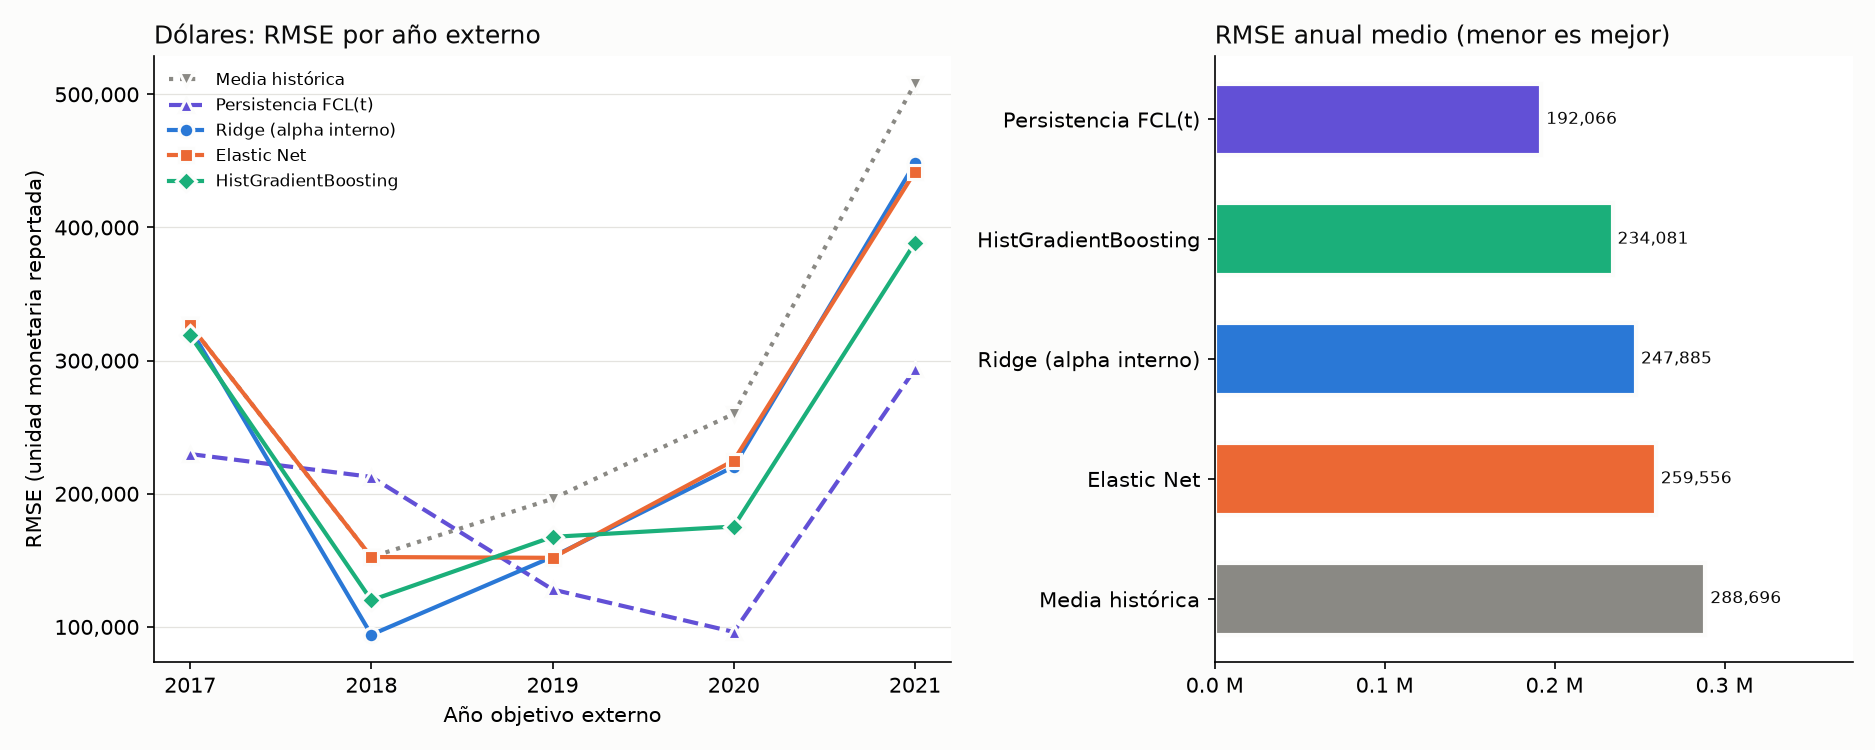

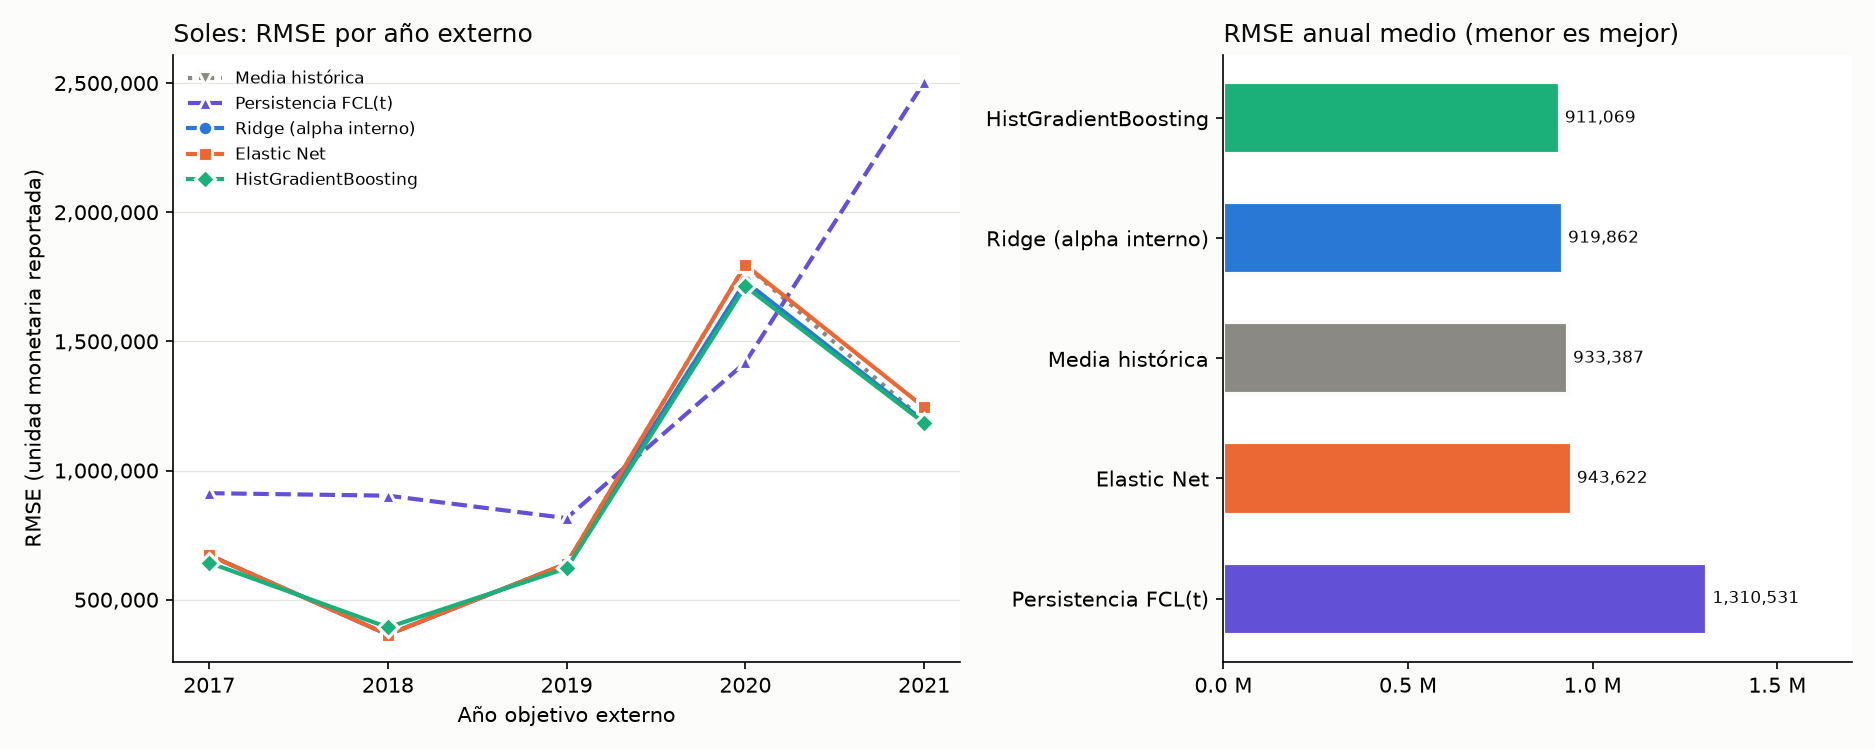

In [8]:
for m in ['dolares', 'soles']:
    display(Image(filename=str(cm.OUT / 'graficos' / f'comparacion_{m}.png'), width=900))

En dólares, la persistencia solo pierde en 2018. En soles, los tres modelos siguen casi la misma trayectoria y la persistencia se separa en 2017–2019 y 2021.

**9. Pruebas automatizadas**
Aislamiento de prueba, separación temporal, ajuste del preprocesamiento y del objetivo, filas comunes, años futuros, métricas, reproducción y convergencia.

In [9]:
suite = unittest.defaultTestLoader.loadTestsFromName('tests.test_comparacion_modelos')
def aplanar(s):
    for t in s:
        yield from (aplanar(t) if isinstance(t, unittest.TestSuite) else [t])
resultado = unittest.TextTestRunner(verbosity=1, stream=sys.stdout).run(unittest.TestSuite(t for t in aplanar(suite) if 'notebook' not in t.id()))
assert resultado.wasSuccessful()

.

.

.

.

.

.

... (5 outputs left out)

.

.

.

----------------------------------------------------------------------
Ran 14 tests in 76.078s

OK


Las pruebas pasan, incluidos los controles positivos: detectan la falta de convergencia con pocas iteraciones y el efecto de perturbar años previos sobre el año siguiente.